# NDVI-binned error diagnostic — binary water-level classifier (dry / wet)

Question: does the classifier's error vary with NDVI (canopy amount)?

**Setup**
- Data loading, subfield merge, daily interpolation and 14-day windowing are copied from
  `rice_classifier_3class_single.ipynb` (BLOCKS 1–6) so the samples are identical.
- Binary labels: water level mean `< −1` → dry (0), `≥ −1` → wet (1) (`DRY_THRESHOLD` in the Config cell).
- Out-of-fold (OOF) predictions: grouped K-fold over **field-years** (the original split unit),
  stratified on class, over *all* non-excluded field-years (train + val + test pooled).
- NDVI = (B8 − B4)/(B8 + B4) from the interpolated B4/B8 on the **last day of each 14-day window**
  (the most recent S2 values the model sees). NDVI at the last *real* S2 acquisition is also stored.
- Period = half-month of the prediction date (years pooled).

Nothing is written back to the original notebook. Tables and figures are saved to `outputs/ndvi_error/thr_-1/`.

In [1]:
import calendar, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix
from scipy.stats import spearmanr, pointbiserialr
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200)
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 17, 'axes.labelsize': 15,
    'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'legend.fontsize': 13, 'legend.title_fontsize': 13, 'figure.titlesize': 20,
})

SEED = 42
np.random.seed(SEED)

## Config (copied from the classifier notebook unless noted)

In [2]:
LOOKBACK = 14
# Dry if water level mean < DRY_THRESHOLD, wet otherwise.
# Note: the classifier notebook defines LOW_THRESHOLD = -1, but the active line in its get_label()
# is `if value < 0`, and its recorded 2-bin test counts (133 dry / 328 wet) match 0.
DRY_THRESHOLD = -1
THR_TAG = f'dry: water level < {DRY_THRESHOLD}'
OUT_DIR = f'outputs/ndvi_error/thr_{DRY_THRESHOLD}'
os.makedirs(OUT_DIR, exist_ok=True)

# 2-bin hyperparameters from the project context doc (n_estimators=200, max_depth=4, lr=0.05).
# subsample / colsample_bytree = 0.8 kept from the notebook's XGB_PARAMS.
# NOTE: the notebook itself still has the 3-bin params (300 trees, depth 6, multi:softmax).
XGB_PARAMS = dict(
    n_estimators     = 200,
    max_depth        = 4,
    learning_rate    = 0.05,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    objective        = 'binary:logistic',
    eval_metric      = 'logloss',
    random_state     = SEED,
)

TEST_FIELD_YEARS    = ['5_2022', '14_2023', '55_2021', '11_2024',
                       '7_2021', '8_2022', '2_2024', '9_2023']
EXCLUDE_FIELD_YEARS = ['55_2022', '66_2022', '77_2022', '88_2022']
TRAIN_FRAC = 0.80

N_FOLDS  = 5
GROUP_BY = 'field_year'   # 'field_year' (original split unit) or 'field' (stricter: no field in both train and test)

NDVI_BINS   = [-np.inf, 0.3, 0.5, 0.7, np.inf]
NDVI_LABELS = ['<0.3', '0.3–0.5', '0.5–0.7', '≥0.7']

NDVI_FILES = [
    "final/sentinel2_2021_full - final - sentinel2_2021_full - Sheet1 (1).csv.csv",
    "final/sentinel2_2022_full - final - sentinel2_2022_full - Sheet1 (1).csv.csv",
    "final/sentinel2_2023_full - final - sentinel2_2023_full - Sheet1 (1).csv.csv",
    "final/pls_sentinel2_2024_full - final - sentinel2_2024_full - Sheet1 (1).csv.csv",
]
WL_FILES = [
    'final/all_daily_2021_averages_col22 (1).csv',
    'final/all_daily_averages_2022_col22.csv',
    'final/all_daily_averages_2023_col22.csv',
    'final/all_daily_averages_2024_final_col22.csv',
]
S1_FILES = [
    'final/2021_sentinel_1 - Sheet1.csv',
    'final/2022_sentinel_1 - Sheet1.csv',
    'final/2023_sentinel1 - Sheet1 (1).csv',
    'final/2024_sentinel_1 - Sheet1.csv',
]

WL_COLS = {'field':'runkle', 'date':'date', 'mean':'daily_mean',
           'min':'daily_min', 'max':'daily_max', 'std':'daily_std_dev'}
S1_COLS = {'field':'field', 'date':'date', 'vv':'VV', 'vh':'VH',
           'vv_vh_ratio_db':'VV_VH_ratio_db',
           'vv_vh_ratio_lin':'VV_VH_ratio_lin', 'waterlike':'waterlike'}

S2_COLS_FEAT = ['b2','b3','b4','b5','b6','b7','b8','b8a','b11','b12',
                'ndvi','ndwi','solar_zenith','solar_azimuth',
                'view_zenith_b4','view_azimuth_b4',
                'view_zenith_b8','view_azimuth_b8']
S1_COLS_FEAT = ['vv','vh','vv_vh_ratio_db','vv_vh_ratio_lin','waterlike']
INPUT_COLS   = S2_COLS_FEAT + S1_COLS_FEAT     # SENSOR_MODE = 'both'
print(f'{len(INPUT_COLS)} features x {LOOKBACK} days = {len(INPUT_COLS)*LOOKBACK} columns per sample')

23 features x 14 days = 322 columns per sample


## Load & merge (identical to classifier BLOCKS 3–5)

In [3]:
def find_col(df, keyword):
    kw = keyword.lower()
    matches = [c for c in df.columns if kw in c.lower()]
    if not matches:
        raise ValueError(f"No column matching '{keyword}' found. Available: {list(df.columns)}")
    return matches[0]


def load_ndvi(path):
    df = pd.read_csv(path)
    df = df.rename(columns={find_col(df, 'field'): 'field', find_col(df, 'date'): 'date'})
    df['date']  = pd.to_datetime(df['date'])
    df['field'] = df['field'].astype(int)
    col_lower = {c.lower(): c for c in df.columns}
    all_bands = ['B2','B3','B4','B5','B6','B7','B8','B8A','B11','B12','NDVI','NDWI',
                 'solar_zenith','solar_azimuth',
                 'view_zenith_B4','view_azimuth_B4','view_zenith_B8','view_azimuth_B8']
    band_rename = {col_lower[b.lower()]: b.lower() for b in all_bands if b.lower() in col_lower}
    df = df.rename(columns=band_rename)
    s2_cols = [b.lower() for b in all_bands if b.lower() in df.columns]
    for b in s2_cols:
        df[b] = pd.to_numeric(df[b], errors='coerce')
    return df[['field', 'date'] + s2_cols]


def load_waterlevel(path):
    df = pd.read_csv(path)
    df = df.rename(columns={find_col(df, s): f for f, s in WL_COLS.items()})
    df['date']  = pd.to_datetime(df['date'])
    df['field'] = df['field'].astype(int)
    for c in ['mean', 'min', 'max', 'std']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df[['field', 'date', 'mean', 'min', 'max', 'std']]


def load_sentinel1(path):
    df = pd.read_csv(path)
    df = df.rename(columns={find_col(df, s): f for f, s in S1_COLS.items()})
    df['date']  = pd.to_datetime(df['date'])
    df['field'] = df['field'].astype(int)
    for c in S1_COLS_FEAT:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df[['field', 'date'] + S1_COLS_FEAT]


def merge_subfields(df):
    numeric_cols = [c for c in df.columns if c not in ('field', 'date', 'name', 'field_year')]
    parts = []
    for fA, fB, f_new in [(40, 400, 4), (140, 1400, 14)]:
        has_A, has_B = fA in df['field'].values, fB in df['field'].values
        if not has_A and not has_B:
            continue
        rows_A, rows_B = df[df['field'] == fA], df[df['field'] == fB]
        if has_A and has_B:
            merged = pd.concat([rows_A, rows_B]).groupby('date', as_index=False)[numeric_cols].mean()
        else:
            merged = (rows_A if has_A else rows_B).copy()
        merged['field'] = f_new
        parts.append(merged)
    df_kept = df[~df['field'].isin({40, 400, 140, 1400})].copy()
    df_out = pd.concat([df_kept] + parts, ignore_index=True) if parts else df_kept
    return df_out.sort_values(['field', 'date']).reset_index(drop=True)


ndvi_df = merge_subfields(pd.concat([load_ndvi(p) for p in NDVI_FILES], ignore_index=True))
wl_df   = merge_subfields(pd.concat([load_waterlevel(p) for p in WL_FILES], ignore_index=True))
s1_df   = merge_subfields(pd.concat([load_sentinel1(p) for p in S1_FILES], ignore_index=True))
for _df in [ndvi_df, wl_df, s1_df]:
    _df['field_year'] = _df['field'].astype(int).astype(str) + '_' + _df['date'].dt.year.astype(str)

common_keys = sorted(set(ndvi_df['field_year']) & set(wl_df['field_year']) & set(s1_df['field_year']))
print(f'S2 rows {len(ndvi_df)}, WL rows {len(wl_df)}, S1 rows {len(s1_df)}')
print(f'Common field-years: {len(common_keys)}')

S2 rows 1516, WL rows 6623, S1 rows 977
Common field-years: 61


In [4]:
field_data = {}
for key in common_keys:
    if key in EXCLUDE_FIELD_YEARS:
        continue
    nd = ndvi_df[ndvi_df['field_year'] == key][['date'] + S2_COLS_FEAT]
    s1 = s1_df  [s1_df  ['field_year'] == key][['date'] + S1_COLS_FEAT]
    wl = wl_df  [wl_df  ['field_year'] == key][['date', 'mean', 'min', 'max', 'std']]
    nd, s1, wl = [d[d['date'].dt.month <= 7] for d in (nd, s1, wl)]
    nd = nd.groupby('date')[S2_COLS_FEAT].mean()
    s1 = s1.groupby('date')[S1_COLS_FEAT].mean()
    wl = wl.groupby('date')[['mean', 'min', 'max', 'std']].mean()
    start = min(wl.index.min(), nd.index.min(), s1.index.min())
    end   = max(wl.index.max(), nd.index.max(), s1.index.max())
    daily_idx = pd.date_range(start, end, freq='D')
    nd_daily = nd.reindex(daily_idx).interpolate(method='time').ffill().bfill()
    s1_daily = s1.reindex(daily_idx).interpolate(method='time').ffill().bfill()
    wl_daily = wl.reindex(daily_idx)
    df = pd.concat([wl_daily, nd_daily, s1_daily], axis=1).dropna(subset=['mean'])
    if len(df) < LOOKBACK + 1:
        continue
    field_data[key] = df
print(f'Field-years ready: {len(field_data)}')

Field-years ready: 57


## Windows + per-sample metadata

Same windowing as BLOCK 6. For each sample we also keep: prediction date, NDVI and VH on the last
window day, and NDVI / date of the last real (non-interpolated, non-NaN) S2 acquisition on or
before the last window day.

In [5]:
# Real S2 acquisitions (cloud-free rows: B4 and B8 present), duplicates on one date averaged
s2_real = (ndvi_df.dropna(subset=['b4', 'b8'])
                  .groupby(['field_year', 'date'])[['b4', 'b8']].mean().reset_index())
s2_real['ndvi_real'] = (s2_real['b8'] - s2_real['b4']) / (s2_real['b8'] + s2_real['b4'])
s2_real_by_key = {k: g.set_index('date')['ndvi_real'].sort_index() for k, g in s2_real.groupby('field_year')}

X_list, y_list, meta_rows = [], [], []
for key, df in field_data.items():
    X_raw = df[INPUT_COLS].values.astype(np.float32)
    wl    = df['mean'].values
    idx   = df.index
    real  = s2_real_by_key.get(key, pd.Series(dtype=float))
    for i in range(LOOKBACK, len(df)):
        X_list.append(X_raw[i - LOOKBACK:i].flatten())
        y_list.append(0 if wl[i] < DRY_THRESHOLD else 1)
        last = idx[i - 1]
        prior = real[real.index <= last]
        meta_rows.append({
            'field_year': key,
            'field': key.split('_')[0],
            'date': idx[i],
            'last_window_day': last,
            'window_span_days': (last - idx[i - LOOKBACK]).days + 1,
            'water_level': wl[i],
            'b4': df['b4'].iloc[i - 1],
            'b8': df['b8'].iloc[i - 1],
            'vh_db': df['vh'].iloc[i - 1],
            'ndvi_s2col': df['ndvi'].iloc[i - 1],
            'ndvi_real': prior.iloc[-1] if len(prior) else np.nan,
            'last_real_s2': prior.index[-1] if len(prior) else pd.NaT,
        })

X = np.vstack(X_list)
y = np.array(y_list)
meta = pd.DataFrame(meta_rows)
meta['true'] = y
meta['ndvi'] = (meta['b8'] - meta['b4']) / (meta['b8'] + meta['b4'])
meta['days_since_real_s2'] = (meta['last_window_day'] - meta['last_real_s2']).dt.days
meta['doy'] = meta['date'].dt.dayofyear
meta['year'] = meta['date'].dt.year
meta['month'] = meta['date'].dt.month
meta['period'] = meta['date'].apply(lambda d: f"{calendar.month_abbr[d.month]}-{1 if d.day <= 15 else 2}")
PERIOD_ORDER = [f'{calendar.month_abbr[m]}-{h}' for m in range(1, 13) for h in (1, 2)]
PERIOD_ORDER = [p for p in PERIOD_ORDER if p in set(meta['period'])]
meta['period'] = pd.Categorical(meta['period'], categories=PERIOD_ORDER, ordered=True)
meta['ndvi_bin'] = pd.cut(meta['ndvi'], NDVI_BINS, labels=NDVI_LABELS, right=False)

print(f'Samples: {len(y)}  |  dry={int((y==0).sum())}  wet={int((y==1).sum())}  |  field-years={meta.field_year.nunique()}')
print(f'NDVI NaN: {meta.ndvi.isna().sum()}')
print(f"Max |ndvi (from B4/B8) - NDVI column| on last window day: {(meta.ndvi - meta.ndvi_s2col).abs().max():.4f}")
print(f"Samples whose 14 rows span >14 calendar days (gaps in water-level record): {(meta.window_span_days > LOOKBACK).sum()}")
print(f"Samples with no real S2 acquisition on/before last window day (S2 features back-filled from later dates): {meta.last_real_s2.isna().sum()}")
print('\nDays since last real S2 acquisition (at last window day):')
print(meta['days_since_real_s2'].describe().round(1).to_string())

Samples: 3432  |  dry=563  wet=2869  |  field-years=57
NDVI NaN: 0
Max |ndvi (from B4/B8) - NDVI column| on last window day: 0.1004
Samples whose 14 rows span >14 calendar days (gaps in water-level record): 52
Samples with no real S2 acquisition on/before last window day (S2 features back-filled from later dates): 77

Days since last real S2 acquisition (at last window day):
count    3355.0
mean        5.0
std         5.5
min         0.0
25%         1.0
50%         3.0
75%         7.0
max        29.0


## Sanity check: reproduce the fixed split

Train on the notebook's train field-years, evaluate on `TEST_FIELD_YEARS`, to compare with the
recorded 2-bin test result (dry recall 61/133, wet recall 316/328). Those recorded counts correspond to a
threshold of 0, so the class totals here (threshold −1) differ.

In [6]:
keys = meta['field_year'].values
remaining = [k for k in field_data if k not in TEST_FIELD_YEARS]
train_keys = remaining[:int(len(remaining) * TRAIN_FRAC)]
tr, te = np.isin(keys, train_keys), np.isin(keys, TEST_FIELD_YEARS)

sc = StandardScaler().fit(X[tr])
m = XGBClassifier(**XGB_PARAMS).fit(sc.transform(X[tr]), y[tr])
p = m.predict(sc.transform(X[te]))
cm = confusion_matrix(y[te], p, labels=[0, 1])
print('Fixed-split test confusion matrix (rows=true dry/wet, cols=pred dry/wet):')
print(cm)
print(f'dry recall {cm[0,0]}/{cm[0].sum()}   wet recall {cm[1,1]}/{cm[1].sum()}')

Fixed-split test confusion matrix (rows=true dry/wet, cols=pred dry/wet):
[[ 42  73]
 [  7 339]]
dry recall 42/115   wet recall 339/346


## Out-of-fold predictions

`StratifiedGroupKFold` with groups = `GROUP_BY`. Scaler fit on each training fold only.

In [7]:
groups = meta[GROUP_BY].values
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

meta['pred'] = -1
meta['prob_wet'] = np.nan
meta['fold'] = -1
for k, (tr_idx, te_idx) in enumerate(cv.split(X, y, groups)):
    sc = StandardScaler().fit(X[tr_idx])
    mdl = XGBClassifier(**XGB_PARAMS).fit(sc.transform(X[tr_idx]), y[tr_idx])
    Xte = sc.transform(X[te_idx])
    meta.loc[te_idx, 'pred'] = mdl.predict(Xte)
    meta.loc[te_idx, 'prob_wet'] = mdl.predict_proba(Xte)[:, 1]
    meta.loc[te_idx, 'fold'] = k
    yt = y[te_idx]
    print(f'fold {k}: n={len(te_idx):4d}  groups={len(set(groups[te_idx])):2d}  dry={int((yt==0).sum()):3d}  wet={int((yt==1).sum()):4d}')

assert (meta['pred'] >= 0).all()
meta['error'] = (meta['pred'] != meta['true']).astype(int)
cm = confusion_matrix(meta['true'], meta['pred'], labels=[0, 1])
print('\nOOF confusion matrix (rows=true dry/wet, cols=pred dry/wet):')
print(cm)
print(f'OOF dry recall {cm[0,0]}/{cm[0].sum()} = {cm[0,0]/cm[0].sum():.3f}   '
      f'wet recall {cm[1,1]}/{cm[1].sum()} = {cm[1,1]/cm[1].sum():.3f}')
print(f'OOF dry precision {cm[0,0]}/{cm[:,0].sum()} = {cm[0,0]/cm[:,0].sum():.3f}   '
      f'wet precision {cm[1,1]}/{cm[:,1].sum()} = {cm[1,1]/cm[:,1].sum():.3f}')

fold 0: n= 713  groups=11  dry=117  wet= 596


fold 1: n= 691  groups=11  dry=125  wet= 566


fold 2: n= 658  groups=12  dry=117  wet= 541


fold 3: n= 688  groups=12  dry= 93  wet= 595


fold 4: n= 682  groups=11  dry=111  wet= 571

OOF confusion matrix (rows=true dry/wet, cols=pred dry/wet):
[[ 270  293]
 [ 110 2759]]
OOF dry recall 270/563 = 0.480   wet recall 2759/2869 = 0.962
OOF dry precision 270/380 = 0.711   wet precision 2759/3052 = 0.904


## 1. Metrics per NDVI bin

Recall = correct / true class count; precision = correct / predicted class count
(`n_pred_dry`, `n_pred_wet`). Precision within a bin depends on that bin's dry/wet mix.
Recall and precision CIs are Wilson 95% intervals treating days as independent. Consecutive days from one
field-year share 13 of 14 window days, so these intervals are narrower than the real uncertainty;
`n_fy_dry` shows how many field-years the dry samples come from.

In [8]:
def rate_ci(k, n):
    if n == 0:
        return np.nan, np.nan, np.nan
    lo, hi = proportion_confint(k, n, method='wilson')
    return k / n, lo, hi


def group_metrics(g):
    dry, wet = g[g.true == 0], g[g.true == 1]
    dr, dlo, dhi = rate_ci(int((dry.pred == 0).sum()), len(dry))
    wr, wlo, whi = rate_ci(int((wet.pred == 1).sum()), len(wet))
    pdry, pwet = g[g.pred == 0], g[g.pred == 1]
    dp, dplo, dphi = rate_ci(int((pdry.true == 0).sum()), len(pdry))
    wp, wplo, wphi = rate_ci(int((pwet.true == 1).sum()), len(pwet))
    return pd.Series({
        'n': len(g), 'n_dry': len(dry), 'n_wet': len(wet),
        'n_fy_dry': dry.field_year.nunique(), 'n_fy_wet': wet.field_year.nunique(),
        'dry_correct': int((dry.pred == 0).sum()), 'dry_recall': dr, 'dry_lo': dlo, 'dry_hi': dhi,
        'wet_correct': int((wet.pred == 1).sum()), 'wet_recall': wr, 'wet_lo': wlo, 'wet_hi': whi,
        'n_pred_dry': len(pdry), 'dry_precision': dp, 'dry_p_lo': dplo, 'dry_p_hi': dphi,
        'n_pred_wet': len(pwet), 'wet_precision': wp, 'wet_p_lo': wplo, 'wet_p_hi': wphi,
        'balanced_acc': np.nanmean([dr, wr]) if len(dry) and len(wet) else np.nan,
    })


bin_tbl = meta.groupby('ndvi_bin', observed=False).apply(group_metrics)
_int = ['n', 'n_dry', 'n_wet', 'n_fy_dry', 'n_fy_wet', 'n_pred_dry', 'n_pred_wet']
bin_tbl[_int] = bin_tbl[_int].astype(int)
bin_tbl.to_csv(f'{OUT_DIR}/metrics_by_ndvi_bin.csv')
bin_tbl.round(3)

,n,n_dry,n_wet,n_fy_dry,n_fy_wet,dry_correct,dry_recall,dry_lo,dry_hi,wet_correct,...,wet_hi,n_pred_dry,dry_precision,dry_p_lo,dry_p_hi,n_pred_wet,wet_precision,wet_p_lo,wet_p_hi,balanced_acc
ndvi_bin,,,,,,,,,,,,,,,,,,,,,
<0.3,466,257,209,25,26,179.0,0.696,0.638,0.749,154.0,...,0.792,234,0.765,0.707,0.815,232,0.664,0.601,0.721,0.717
0.3–0.5,411,139,272,17,48,90.0,0.647,0.565,0.722,229.0,...,0.880,133,0.677,0.593,0.750,278,0.824,0.775,0.864,0.745
0.5–0.7,372,25,347,8,54,0.0,0.000,0.000,0.133,341.0,...,0.992,6,0.000,0.000,0.390,366,0.932,0.901,0.953,0.491
≥0.7,2183,142,2041,19,55,1.0,0.007,0.001,0.039,2035.0,...,0.999,7,0.143,0.026,0.513,2176,0.935,0.924,0.945,0.502


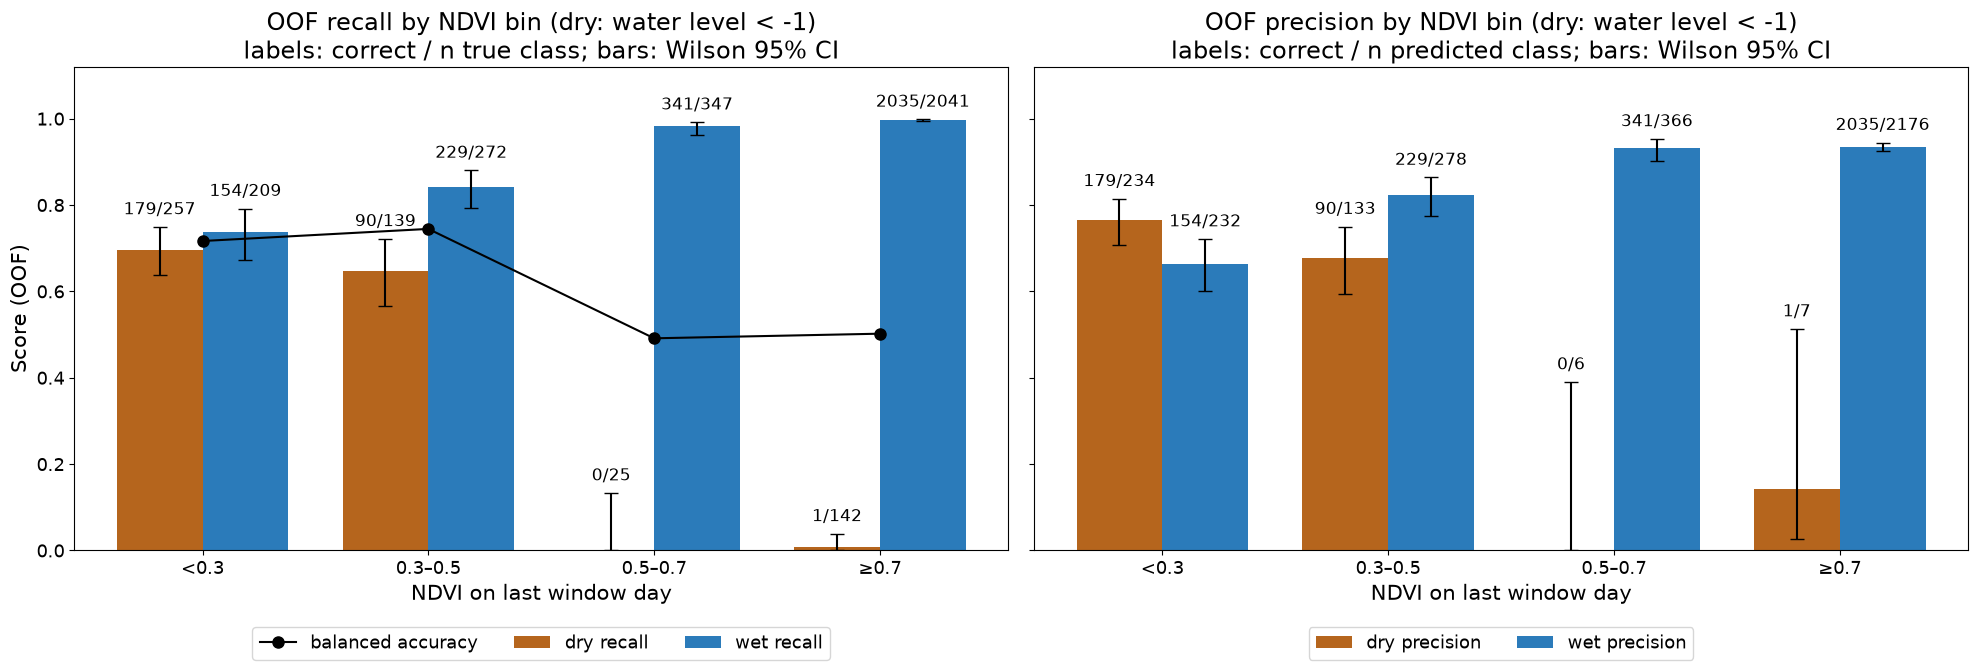

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(20, 7), sharey=True)
xs = np.arange(len(bin_tbl))
w = 0.38
panels = [('recall', 'lo', 'hi', 'correct', 'n_{c}', 'true class'),
          ('precision', 'p_lo', 'p_hi', None, 'n_pred_{c}', 'predicted class')]
for ax, (metric, lo, hi, _, nkey, denom) in zip(axes, panels):
    for off, cls, col in [(-w/2, 'dry', '#b5651d'), (w/2, 'wet', '#2b7bba')]:
        r = bin_tbl[f'{cls}_{metric}'].values
        err = np.vstack([r - bin_tbl[f'{cls}_{lo}'].values, bin_tbl[f'{cls}_{hi}'].values - r]).clip(min=0)
        ax.bar(xs + off, np.nan_to_num(r), w, color=col, label=f'{cls} {metric}', yerr=np.nan_to_num(err), capsize=5)
        n = bin_tbl[nkey.format(c=cls)].values
        k = np.rint(np.nan_to_num(r) * n).astype(int)
        for x, h, kk, nn in zip(xs + off, bin_tbl[f'{cls}_{hi}'].values, k, n):
            ax.text(x, (0 if np.isnan(h) else h) + 0.02, f'{kk}/{nn}', ha='center', va='bottom', fontsize=12)
    if metric == 'recall':
        ax.plot(xs, bin_tbl['balanced_acc'], 'ko-', ms=8, label='balanced accuracy')
    ax.set_xticks(xs, [f'{b}' for b in bin_tbl.index])
    ax.set_xlabel('NDVI on last window day')
    ax.set_ylim(0, 1.12)
    ax.set_title(f'OOF {metric} by NDVI bin ({THR_TAG})\nlabels: correct / n {denom}; bars: Wilson 95% CI')
    ax.legend(loc='upper center', ncol=3 if metric == 'recall' else 2, bbox_to_anchor=(0.5, -0.14))
axes[0].set_ylabel('Score (OOF)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/recall_precision_by_ndvi_bin.png', dpi=150, bbox_inches='tight')
plt.show()

### Overall correlation between error and NDVI (per true class)

Point-biserial r between `error` (0/1) and NDVI, computed within each true class (days treated as
independent — see caveat above).

In [10]:
rows = []
for cls, name in [(0, 'true dry'), (1, 'true wet')]:
    g = meta[meta.true == cls]
    r, p = pointbiserialr(g['error'], g['ndvi'])
    rows.append({'subset': name, 'n': len(g), 'n_errors': int(g.error.sum()),
                 'mean_ndvi_correct': g.loc[g.error == 0, 'ndvi'].mean(),
                 'mean_ndvi_error': g.loc[g.error == 1, 'ndvi'].mean(),
                 'pointbiserial_r': r, 'p_value': p})
corr_tbl = pd.DataFrame(rows)
corr_tbl.round(4)

,subset,n,n_errors,mean_ndvi_correct,mean_ndvi_error,pointbiserial_r,p_value
0,true dry,563,293,0.2543,0.5761,0.6130,0.0
1,true wet,2869,110,0.7485,0.3190,-0.3888,0.0


## 2. Separating canopy from date

NDVI rises through the season, so NDVI and date are confounded. Two views:
(a) within-period tables of dry recall by NDVI bin; (b) logistic regressions.

In [11]:
r_s, p_s = spearmanr(meta['ndvi'], meta['doy'])
r_d, p_d = spearmanr(meta.loc[meta.true == 0, 'ndvi'], meta.loc[meta.true == 0, 'doy'])
print(f'Spearman(NDVI, day-of-year): all samples rho={r_s:.3f} (p={p_s:.2g});  true-dry only rho={r_d:.3f} (p={p_d:.2g})')

Spearman(NDVI, day-of-year): all samples rho=0.668 (p=0);  true-dry only rho=0.618 (p=1.3e-60)


### (a) Dry recall by half-month period × NDVI bin (cell text = correct/n)

In [12]:
dry = meta[meta.true == 0]
k_tab = dry.assign(ok=(dry.pred == 0).astype(int)).pivot_table(
    index='period', columns='ndvi_bin', values='ok', aggfunc='sum', observed=False).fillna(0)
n_tab = dry.pivot_table(index='period', columns='ndvi_bin', values='true',
                        aggfunc='size', observed=False).fillna(0)
k_tab, n_tab = k_tab.reindex(index=PERIOD_ORDER, columns=NDVI_LABELS).fillna(0), n_tab.reindex(index=PERIOD_ORDER, columns=NDVI_LABELS).fillna(0)
rec_tab = k_tab / n_tab.replace(0, np.nan)

cell_txt = k_tab.astype(int).astype(str) + '/' + n_tab.astype(int).astype(str)
cell_txt = cell_txt.where(n_tab > 0, '')
pd.concat({'dry_recall': rec_tab.round(2), 'correct/n': cell_txt}, axis=1).to_csv(f'{OUT_DIR}/dry_recall_period_x_ndvi.csv')
cell_txt

ndvi_bin,<0.3,0.3–0.5,0.5–0.7,≥0.7
period,,,,
Apr-2,2/2,,,
May-1,47/60,,,
May-2,87/105,36/50,,
Jun-1,7/30,29/51,0/12,0/10
Jun-2,22/31,25/38,0/5,1/46
Jul-1,13/23,,,0/46
Jul-2,1/6,,0/8,0/40


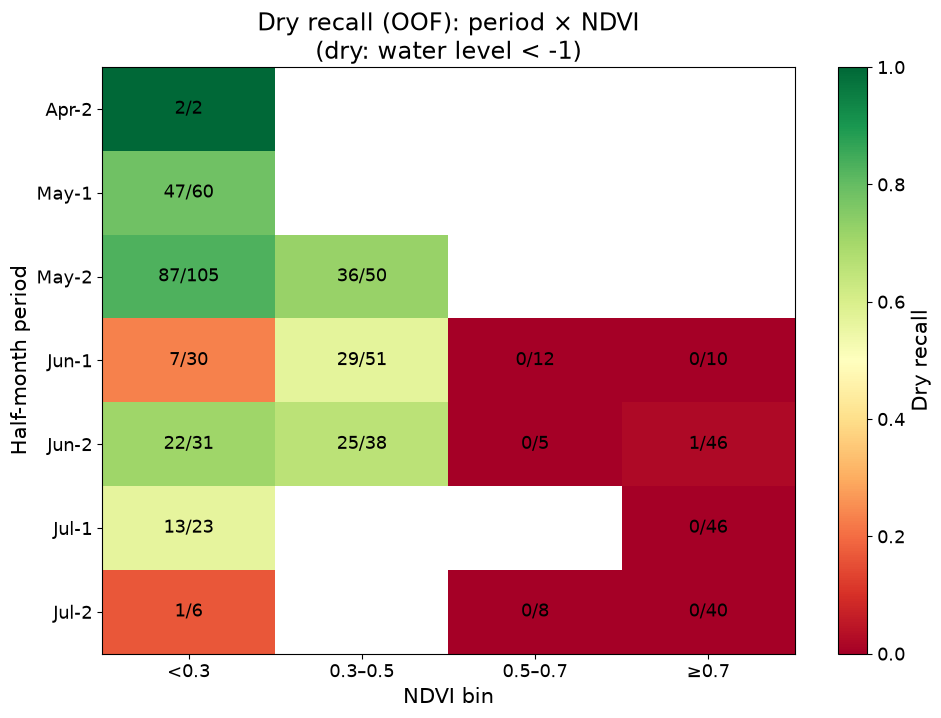

In [13]:
def heat(ax, rec, n, k, title):
    im = ax.imshow(rec.values, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    for i in range(rec.shape[0]):
        for j in range(rec.shape[1]):
            if n.values[i, j] > 0:
                ax.text(j, i, f'{int(k.values[i, j])}/{int(n.values[i, j])}', ha='center', va='center', fontsize=13)
    ax.set_xticks(range(rec.shape[1]), rec.columns)
    ax.set_yticks(range(rec.shape[0]), rec.index)
    ax.set_xlabel('NDVI bin')
    ax.set_ylabel('Half-month period')
    ax.set_title(f'{title}\n({THR_TAG})')
    return im

fig, ax = plt.subplots(figsize=(10, 0.7 * len(PERIOD_ORDER) + 2.5))
im = heat(ax, rec_tab, n_tab, k_tab, 'Dry recall (OOF): period × NDVI')
fig.colorbar(im, ax=ax, label='Dry recall')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/dry_recall_period_x_ndvi.png', dpi=150, bbox_inches='tight')
plt.show()

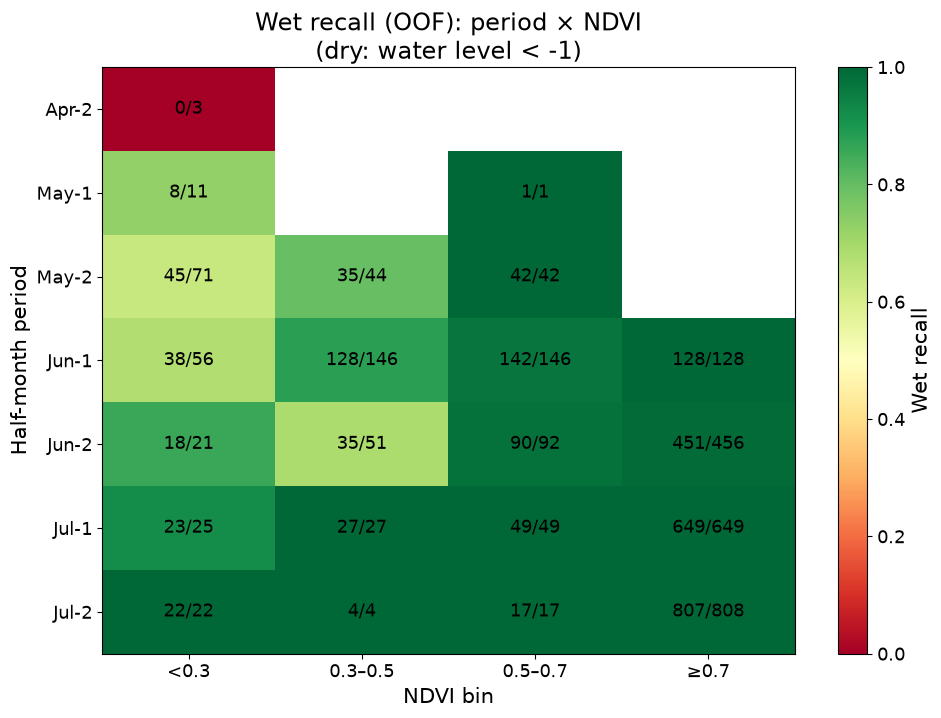

In [14]:
wet = meta[meta.true == 1]
kw = wet.assign(ok=(wet.pred == 1).astype(int)).pivot_table(index='period', columns='ndvi_bin', values='ok', aggfunc='sum', observed=False)
nw = wet.pivot_table(index='period', columns='ndvi_bin', values='true', aggfunc='size', observed=False)
kw, nw = kw.reindex(index=PERIOD_ORDER, columns=NDVI_LABELS).fillna(0), nw.reindex(index=PERIOD_ORDER, columns=NDVI_LABELS).fillna(0)
fig, ax = plt.subplots(figsize=(10, 0.7 * len(PERIOD_ORDER) + 2.5))
im = heat(ax, kw / nw.replace(0, np.nan), nw, kw, 'Wet recall (OOF): period × NDVI')
fig.colorbar(im, ax=ax, label='Wet recall')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/wet_recall_period_x_ndvi.png', dpi=150, bbox_inches='tight')
plt.show()

### (b) Logistic regression: `error ~ NDVI + period`

Fit separately for true-dry and true-wet samples (GLM binomial). NDVI is entered per 0.1 units
(`ndvi10`). Standard errors are cluster-robust by field-year to account for repeated days within a
field-year. Three specifications: NDVI only; NDVI + month (categorical; April pooled with May); NDVI + day-of-year
(linear, per 10 days). Models that fail (e.g. perfect separation) are reported as such.

In [15]:
meta['ndvi10'] = meta['ndvi'] * 10
meta['doy10'] = meta['doy'] / 10
# April has only 5 samples (3 dry, 2 wet), all predicted correctly -> separation; pooled with May
meta['month_c'] = meta['month'].map(lambda m: 'Apr-May' if m <= 5 else calendar.month_abbr[m])
print(pd.crosstab(meta['month_c'], meta['true'].map({0: 'dry', 1: 'wet'})))

SPECS = {
    'NDVI only':        'error ~ ndvi10',
    'NDVI + month':     'error ~ ndvi10 + C(month_c)',
    'NDVI + day-of-year': 'error ~ ndvi10 + doy10',
}

def fit_logit(formula, d):
    d = d.dropna(subset=['ndvi10']).reset_index(drop=True)
    grp = pd.factorize(d['field_year'])[0]
    with warnings.catch_warnings():
        warnings.simplefilter('error', sm.tools.sm_exceptions.PerfectSeparationWarning)
        res = smf.glm(formula, d, family=sm.families.Binomial()).fit(
            cov_type='cluster', cov_kwds={'groups': grp})
    ci = res.conf_int()
    return pd.DataFrame({
        'coef': res.params, 'se': res.bse, 'z': res.tvalues, 'p': res.pvalues,
        'odds_ratio': np.exp(res.params), 'OR_lo': np.exp(ci[0]), 'OR_hi': np.exp(ci[1]),
    }), res, len(d), d['field_year'].nunique()

logit_rows = []
for cls, name in [(0, 'true dry'), (1, 'true wet')]:
    sub = meta[meta.true == cls]
    for spec, f in SPECS.items():
        print(f'── {name} | {spec} | {f}')
        try:
            tbl, res, n, n_cl = fit_logit(f, sub)
            print(f'   n={n}, clusters={n_cl}, errors={int(sub.error.sum())}, AIC={res.aic:.1f}')
            print(tbl.round(4).to_string())
            logit_rows.append(tbl.assign(subset=name, spec=spec, n=n, clusters=n_cl).reset_index(names='term'))
        except Exception as e:
            print(f'   FAILED: {type(e).__name__}: {e}')
        print()

logit_tbl = pd.concat(logit_rows, ignore_index=True)
logit_tbl.to_csv(f'{OUT_DIR}/logit_error_ndvi_period.csv', index=False)
print('NDVI term across specifications:')
logit_tbl[logit_tbl.term == 'ndvi10'][['subset', 'spec', 'n', 'clusters', 'coef', 'se', 'p', 'odds_ratio', 'OR_lo', 'OR_hi']].round(4)

true     dry   wet
month_c           
Apr-May  217   172
Jul      123  1601
Jun      223  1096
── true dry | NDVI only | error ~ ndvi10
   n=563, clusters=34, errors=293, AIC=524.5
             coef      se       z    p  odds_ratio   OR_lo   OR_hi
Intercept -2.7597  0.5562 -4.9619  0.0      0.0633  0.0213  0.1883
ndvi10     0.7629  0.1155  6.6043  0.0      2.1445  1.7100  2.6894

── true dry | NDVI + month | error ~ ndvi10 + C(month_c)
   n=563, clusters=34, errors=293, AIC=496.3
                     coef      se       z       p  odds_ratio   OR_lo    OR_hi
Intercept         -3.0569  0.5501 -5.5573  0.0000      0.0470  0.0160   0.1382
C(month_c)[T.Jul]  2.0922  0.5185  4.0348  0.0001      8.1029  2.9326  22.3886
C(month_c)[T.Jun]  0.7839  0.6464  1.2129  0.2252      2.1901  0.6170   7.7741
ndvi10             0.6789  0.1427  4.7581  0.0000      1.9717  1.4907   2.6079

── true dry | NDVI + day-of-year | error ~ ndvi10 + doy10
   n=563, clusters=34, errors=293, AIC=506.2
             coe

,subset,spec,n,clusters,coef,se,p,odds_ratio,OR_lo,OR_hi
1,true dry,NDVI only,563,34,0.7629,0.1155,0.0,2.1445,1.7100,2.6894
5,true dry,NDVI + month,563,34,0.6789,0.1427,0.0,1.9717,1.4907,2.6079
7,true dry,NDVI + day-of-year,563,34,0.6462,0.1157,0.0,1.9083,1.5212,2.3939
10,true wet,NDVI only,2869,57,-0.7502,0.0938,0.0,0.4723,0.3930,0.5676
14,true wet,NDVI + month,2869,57,-0.6963,0.1220,0.0,0.4984,0.3924,0.6331
16,true wet,NDVI + day-of-year,2869,57,-0.6438,0.1068,0.0,0.5253,0.4261,0.6476


## 3. VH vs NDVI (last window day), coloured by true class

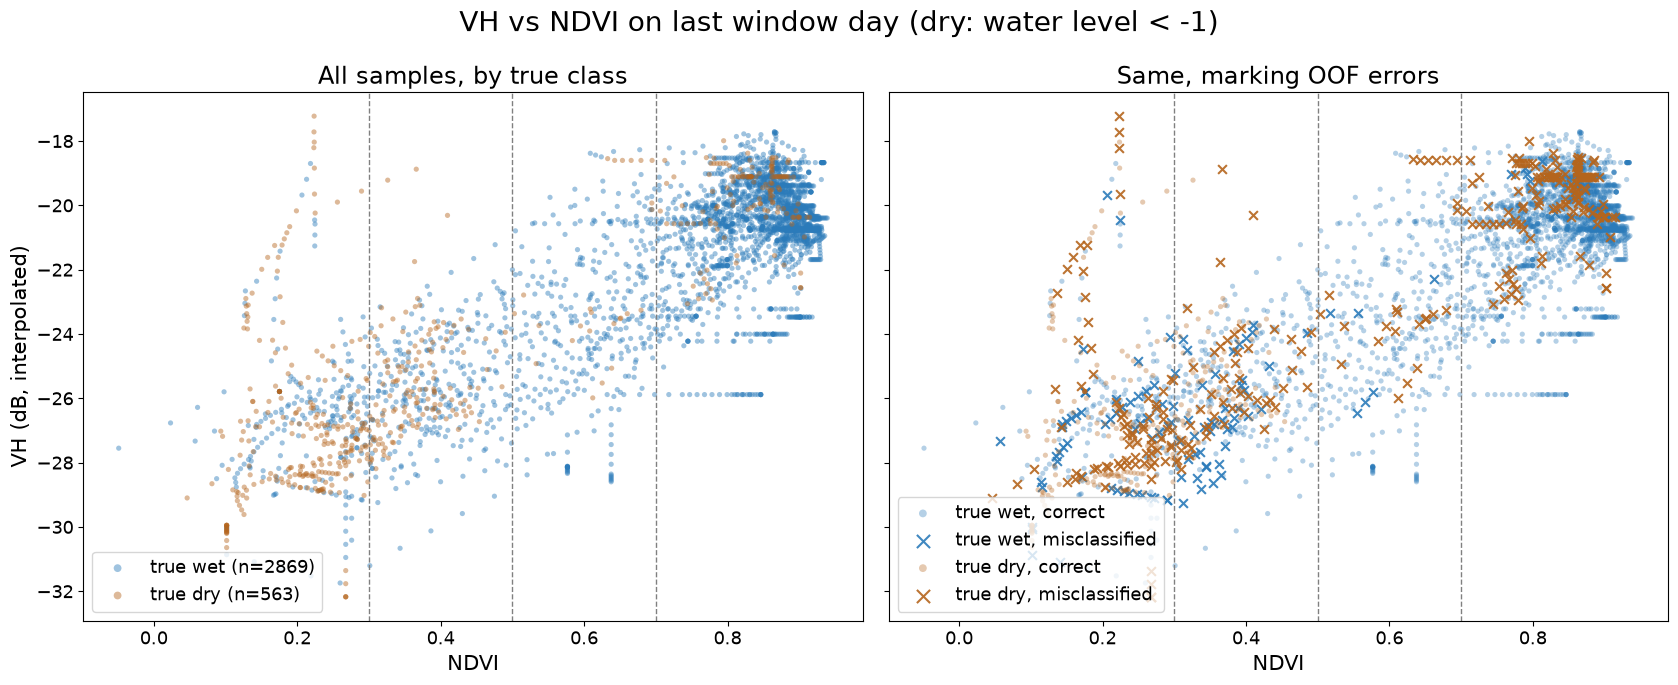

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), sharex=True, sharey=True)

ax = axes[0]
for cls, name, col in [(1, 'wet', '#2b7bba'), (0, 'dry', '#b5651d')]:
    g = meta[meta.true == cls]
    ax.scatter(g.ndvi, g.vh_db, s=14, alpha=0.45, color=col, label=f'true {name} (n={len(g)})', edgecolors='none')
ax.set_title('All samples, by true class')

ax = axes[1]
for cls, name, col in [(1, 'wet', '#2b7bba'), (0, 'dry', '#b5651d')]:
    g = meta[meta.true == cls]
    ax.scatter(g.loc[g.error == 0, 'ndvi'], g.loc[g.error == 0, 'vh_db'], s=14, alpha=0.35, color=col,
               marker='o', edgecolors='none', label=f'true {name}, correct')
    ax.scatter(g.loc[g.error == 1, 'ndvi'], g.loc[g.error == 1, 'vh_db'], s=40, alpha=0.9, color=col,
               marker='x', label=f'true {name}, misclassified')
ax.set_title('Same, marking OOF errors')
fig.suptitle(f'VH vs NDVI on last window day ({THR_TAG})')

for ax in axes:
    for b in [0.3, 0.5, 0.7]:
        ax.axvline(b, color='grey', lw=1, ls='--')
    ax.set_xlabel('NDVI')
    ax.legend(loc='lower left', markerscale=1.5)
axes[0].set_ylabel('VH (dB, interpolated)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/vh_vs_ndvi.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. NDVI vs date for true-dry samples, marking errors

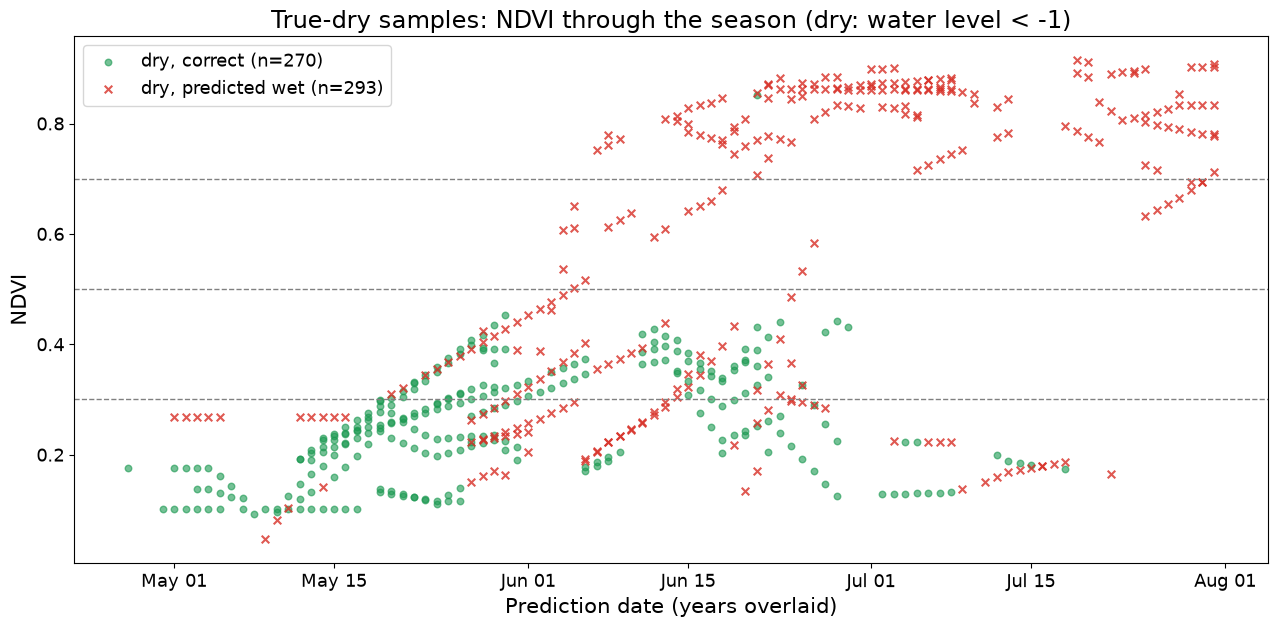

In [17]:
fig, ax = plt.subplots(figsize=(13, 6.5))
d = meta[meta.true == 0]
sc_ = ax.scatter(d.loc[d.error == 0, 'date'].dt.strftime('2000-%m-%d').pipe(pd.to_datetime), d.loc[d.error == 0, 'ndvi'],
                 s=22, color='#1a9850', alpha=0.6, label=f'dry, correct (n={int((d.error==0).sum())})')
ax.scatter(d.loc[d.error == 1, 'date'].dt.strftime('2000-%m-%d').pipe(pd.to_datetime), d.loc[d.error == 1, 'ndvi'],
           s=30, color='#d73027', marker='x', alpha=0.8, label=f'dry, predicted wet (n={int((d.error==1).sum())})')
for b in [0.3, 0.5, 0.7]:
    ax.axhline(b, color='grey', lw=1, ls='--')
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlabel('Prediction date (years overlaid)')
ax.set_ylabel('NDVI')
ax.set_title(f'True-dry samples: NDVI through the season ({THR_TAG})')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/dry_ndvi_vs_date.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Sensitivity: NDVI from the last real S2 acquisition instead of the interpolated value

In [18]:
meta['ndvi_bin_real'] = pd.cut(meta['ndvi_real'], NDVI_BINS, labels=NDVI_LABELS, right=False)
print(f"Samples without a prior real acquisition (excluded here): {meta.ndvi_real.isna().sum()}")
bin_tbl_real = meta.dropna(subset=['ndvi_real']).groupby('ndvi_bin_real', observed=False).apply(group_metrics)
bin_tbl_real.to_csv(f'{OUT_DIR}/metrics_by_ndvi_bin_real_acq.csv')
bin_tbl_real[['n', 'n_dry', 'n_wet', 'dry_correct', 'dry_recall', 'wet_correct', 'wet_recall',
              'n_pred_dry', 'dry_precision', 'n_pred_wet', 'wet_precision', 'balanced_acc']].round(3)

Samples without a prior real acquisition (excluded here): 77


,n,n_dry,n_wet,dry_correct,dry_recall,wet_correct,wet_recall,n_pred_dry,dry_precision,n_pred_wet,wet_precision,balanced_acc
ndvi_bin_real,,,,,,,,,,,,
<0.3,835.0,310.0,525.0,204.0,0.658,447.0,0.851,282.0,0.723,553.0,0.808,0.755
0.3–0.5,252.0,64.0,188.0,44.0,0.688,172.0,0.915,60.0,0.733,192.0,0.896,0.801
0.5–0.7,302.0,35.0,267.0,1.0,0.029,261.0,0.978,7.0,0.143,295.0,0.885,0.503
≥0.7,1966.0,123.0,1843.0,0.0,0.000,1838.0,0.997,5.0,0.000,1961.0,0.937,0.499


## Per-sample output

In [19]:
cols = ['field_year', 'date', 'period', 'water_level', 'true', 'pred', 'prob_wet', 'error', 'fold',
        'ndvi', 'ndvi_bin', 'ndvi_real', 'days_since_real_s2', 'vh_db', 'window_span_days']
meta[cols].to_csv(f'{OUT_DIR}/oof_predictions.csv', index=False)
print(f'Saved {len(meta)} rows to {OUT_DIR}/oof_predictions.csv')

Saved 3432 rows to outputs/ndvi_error/thr_-1/oof_predictions.csv
